# EfficientNet-B0 two-phase Results

Run prefix: `effb0_twophase`

This notebook analyzes the two validation folds for `effb0_twophase_fold0` and `effb0_twophase_fold1`.


In [13]:
import json
import os
import sys
import tempfile
from pathlib import Path


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "outputs").exists():
            return candidate
    fallback = Path("/Users/jaumemalenacortes/Desktop/AABI/AAIB")
    if fallback.exists():
        return fallback
    return start

PROJECT_ROOT = find_project_root()
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "matplotlib-aaib"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)
from sklearn.metrics import (
    average_precision_score,
    auc,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

RUNS_ROOT = PROJECT_ROOT / "outputs" / "runs"
RUN_PREFIX = "effb0_twophase"
DISPLAY_NAME = "EfficientNet-B0 two-phase"
COLOR = "#2E7D32"
FOLD_LS = {0: "-", 1: "--"}

print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"RUNS_ROOT exists: {RUNS_ROOT.exists()} -> {RUNS_ROOT}")


PROJECT_ROOT: /Users/jaumemalenacortes/Desktop/AABI/AAIB
RUNS_ROOT exists: True -> /Users/jaumemalenacortes/Desktop/AABI/AAIB/outputs/runs


In [14]:
def find_runs(prefix: str) -> dict[int, Path]:
    runs = {}
    for fold in [0, 1]:
        candidates = sorted(
            [p for p in RUNS_ROOT.glob(f"{prefix}_fold{fold}*") if p.is_dir()],
            key=lambda p: p.stat().st_mtime,
        )
        if candidates:
            runs[fold] = candidates[-1]
    return runs


def load_json(path: Path) -> dict:
    with open(path) as f:
        return json.load(f)


def load_metrics(run_dir: Path) -> pd.DataFrame:
    path = run_dir / "metrics.jsonl"
    rows = []
    if path.exists():
        with open(path) as f:
            for line in f:
                line = line.strip()
                if line:
                    rows.append(json.loads(line))
    return pd.DataFrame(rows).replace({None: np.nan})


def load_preds(run_dir: Path):
    path = run_dir / "val_preds_best.npz"
    if not path.exists():
        return None
    data = np.load(path, allow_pickle=True)
    return data["logits"], data["labels"], data["subclasses"].astype(str)


runs = find_runs(RUN_PREFIX)
print("Discovered runs:")
if not runs:
    print(f"  {RUN_PREFIX}: no runs found")
else:
    for fold, run_dir in runs.items():
        print(
            f"  fold {fold}: {run_dir.name} "
            f"metrics={(run_dir / 'metrics.jsonl').exists()} "
            f"preds={(run_dir / 'val_preds_best.npz').exists()} "
            f"calibration={(run_dir / 'threshold_calibration.json').exists()}"
        )


Discovered runs:
  fold 0: effb0_twophase_fold0 metrics=True preds=True calibration=True
  fold 1: effb0_twophase_fold1 metrics=True preds=True calibration=True


In [15]:
rows = []
for fold, run_dir in runs.items():
    metrics = load_metrics(run_dir)
    train_result = load_json(run_dir / "train_result.json") if (run_dir / "train_result.json").exists() else {}
    calibration = load_json(run_dir / "threshold_calibration.json") if (run_dir / "threshold_calibration.json").exists() else {}
    best = metrics.loc[metrics["val_pr_auc"].idxmax()] if not metrics.empty and "val_pr_auc" in metrics else pd.Series(dtype=float)
    rows.append({
        "fold": fold,
        "epochs_run": train_result.get("epochs_run", np.nan),
        "best_epoch": int(best.get("epoch", -1)) if not best.empty else np.nan,
        "best_pr_auc": train_result.get("best_pr_auc", calibration.get("pr_auc", np.nan)),
        "eval_pr_auc": calibration.get("pr_auc", np.nan),
        "eval_mcc": calibration.get("mcc", np.nan),
        "eval_npv": calibration.get("npv", np.nan),
        "t_safe": calibration.get("t_safe", np.nan),
        "npv_at_t_safe": calibration.get("npv_at_t_safe", np.nan),
    })

summary_df = pd.DataFrame(rows).sort_values("fold")
display(summary_df)

if not summary_df.empty:
    cv_summary = summary_df[["best_pr_auc", "eval_pr_auc", "eval_mcc", "eval_npv", "npv_at_t_safe"]].agg(["mean", "std"]).round(4)
    display(cv_summary)


,fold,epochs_run,best_epoch,best_pr_auc,eval_pr_auc,eval_mcc,eval_npv,t_safe,npv_at_t_safe
0,0,28,17,0.621112,0.621112,0.541545,0.928769,0.137798,0.950039
1,1,30,19,0.341106,0.341106,0.341981,0.978241,0.990000,0.967491


,best_pr_auc,eval_pr_auc,eval_mcc,eval_npv,npv_at_t_safe
mean,0.4811,0.4811,0.4418,0.9535,0.9588
std,0.1980,0.1980,0.1411,0.0350,0.0123


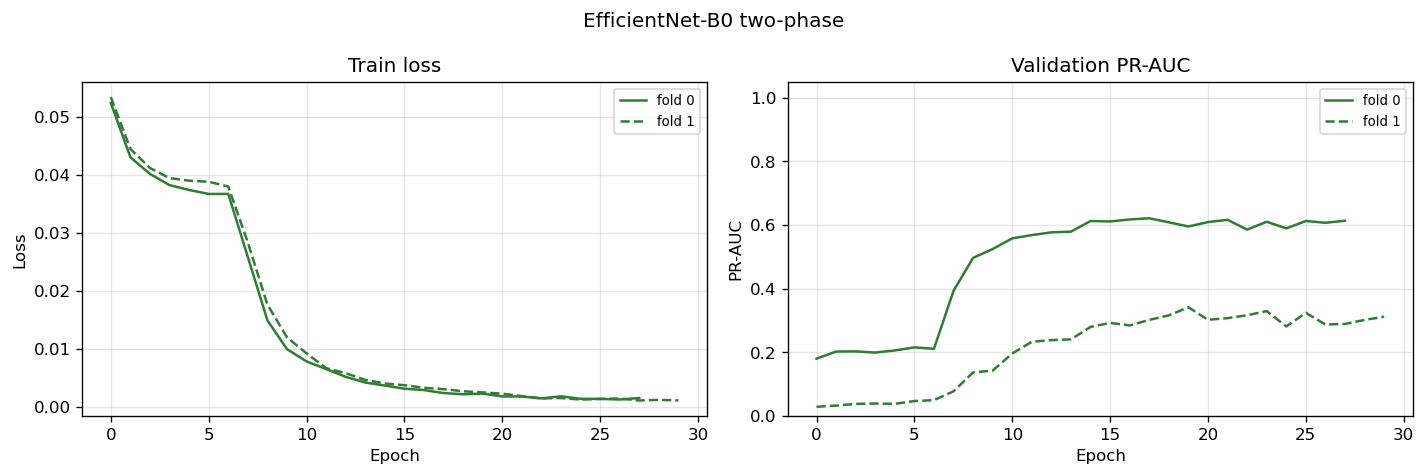

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for fold, run_dir in runs.items():
    metrics = load_metrics(run_dir)
    if metrics.empty:
        continue
    label = f"fold {fold}"
    ls = FOLD_LS[fold]
    if "train_loss" in metrics:
        axes[0].plot(metrics["epoch"], metrics["train_loss"], color=COLOR, ls=ls, label=label)
    if "val_pr_auc" in metrics:
        axes[1].plot(metrics["epoch"], metrics["val_pr_auc"], color=COLOR, ls=ls, label=label)

axes[0].set_title("Train loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].set_title("Validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=8)

fig.suptitle(DISPLAY_NAME)
fig.tight_layout()
plt.show()


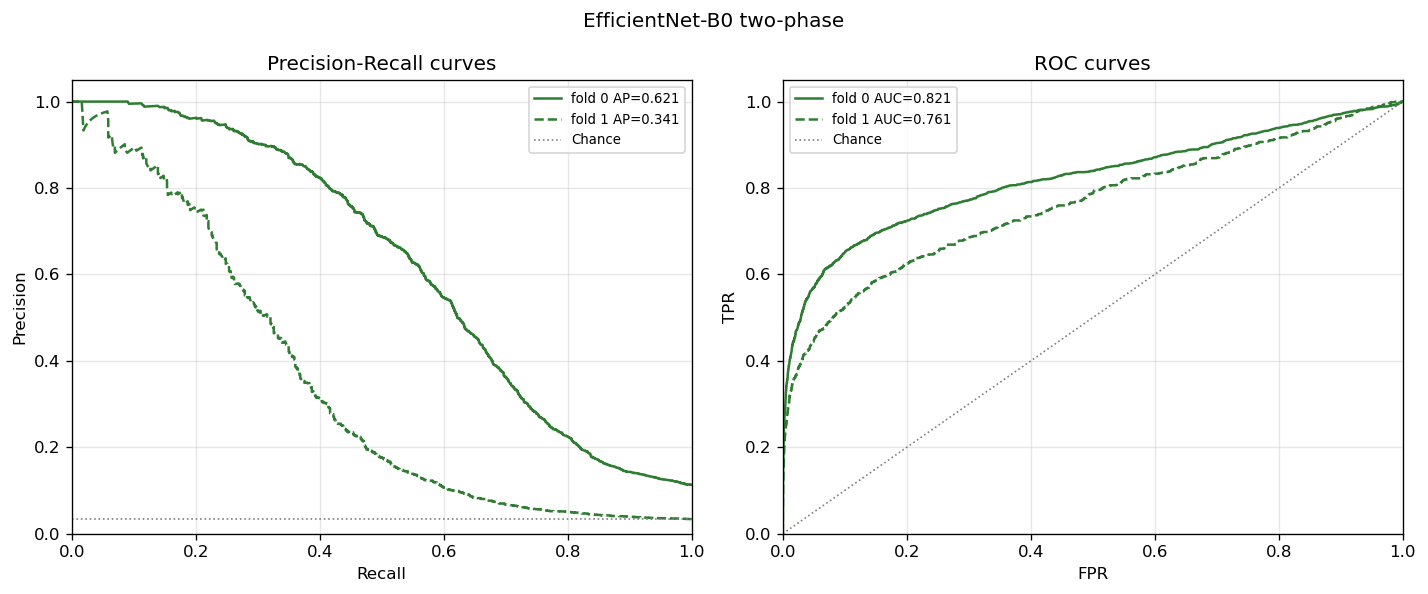

In [17]:
fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))
chance_level = None

for fold, run_dir in runs.items():
    preds = load_preds(run_dir)
    if preds is None:
        continue
    logits, labels, _ = preds
    probs = 1 / (1 + np.exp(-logits))
    chance_level = labels.mean()
    label = f"fold {fold}"
    ls = FOLD_LS[fold]

    precision, recall, _ = precision_recall_curve(labels, probs)
    ap = average_precision_score(labels, probs)
    ax_pr.plot(recall, precision, color=COLOR, ls=ls, label=f"{label} AP={ap:.3f}")

    fpr, tpr, _ = roc_curve(labels, probs)
    roc_auc = auc(fpr, tpr)
    ax_roc.plot(fpr, tpr, color=COLOR, ls=ls, label=f"{label} AUC={roc_auc:.3f}")

if chance_level is not None:
    ax_pr.axhline(chance_level, color="grey", ls=":", lw=1, label="Chance")
ax_roc.plot([0, 1], [0, 1], color="grey", ls=":", lw=1, label="Chance")

ax_pr.set_title("Precision-Recall curves")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.set_xlim(0, 1)
ax_pr.set_ylim(0, 1.05)
ax_pr.grid(True, alpha=0.3)
ax_pr.legend(fontsize=8)

ax_roc.set_title("ROC curves")
ax_roc.set_xlabel("FPR")
ax_roc.set_ylabel("TPR")
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1.05)
ax_roc.grid(True, alpha=0.3)
ax_roc.legend(fontsize=8)

fig.suptitle(DISPLAY_NAME)
fig.tight_layout()
plt.show()


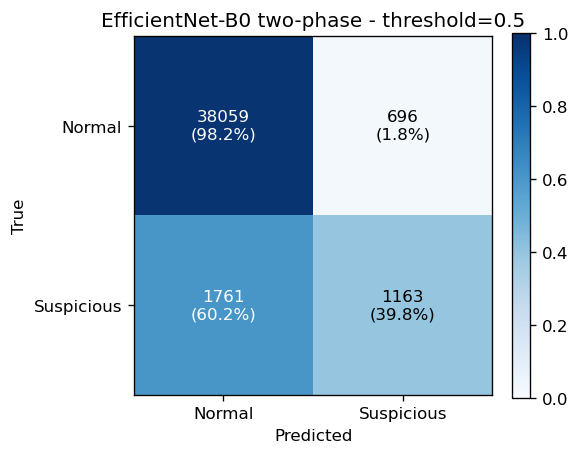

In [18]:
def combined_predictions():
    logits_all, labels_all, subclasses_all = [], [], []
    for run_dir in runs.values():
        preds = load_preds(run_dir)
        if preds is None:
            continue
        logits, labels, subclasses = preds
        logits_all.append(logits)
        labels_all.append(labels)
        subclasses_all.append(subclasses)
    if not logits_all:
        return None
    return np.concatenate(logits_all), np.concatenate(labels_all), np.concatenate(subclasses_all)

combined = combined_predictions()
if combined is None:
    print("No prediction data found.")
else:
    logits, labels, _ = combined
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= 0.5).astype(int)
    cm = confusion_matrix(labels, preds, labels=[0, 1])
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(4.8, 4.2))
    im = ax.imshow(cm_pct, vmin=0, vmax=1, cmap="Blues")
    ax.set_title(f"{DISPLAY_NAME} - threshold=0.5")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Normal", "Suspicious"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Normal", "Suspicious"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(
                j,
                i,
                f"{cm[i, j]}\n({cm_pct[i, j]:.1%})",
                ha="center",
                va="center",
                color="white" if cm_pct[i, j] > 0.5 else "black",
            )
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    plt.show()


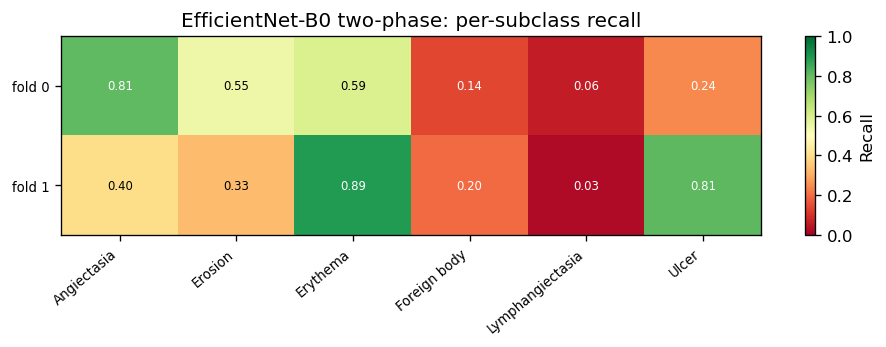

In [19]:
recall_rows = []
for fold, run_dir in runs.items():
    cal_path = run_dir / "threshold_calibration.json"
    if not cal_path.exists():
        continue
    cal = load_json(cal_path)
    for subclass, recall in cal.get("subclass_recall", {}).items():
        recall_rows.append({"fold": fold, "subclass": subclass, "recall": recall})

recall_df = pd.DataFrame(recall_rows)
if recall_df.empty:
    print("No subclass recall data found.")
else:
    pivot = recall_df.pivot_table(index="fold", columns="subclass", values="recall")
    fig, ax = plt.subplots(figsize=(max(8, len(pivot.columns) * 1.2), 3))
    im = ax.imshow(pivot.values, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([f"fold {f}" for f in pivot.index], fontsize=8)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = pivot.iloc[i, j]
            if not np.isnan(value):
                ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7, color="black" if 0.25 < value < 0.75 else "white")
    fig.colorbar(im, ax=ax, label="Recall")
    ax.set_title(f"{DISPLAY_NAME}: per-subclass recall")
    fig.tight_layout()
    plt.show()


In [20]:
for fold, run_dir in runs.items():
    csv_path = run_dir / "eval_predictions_val.csv"
    if csv_path.exists():
        print(f"fold {fold}: {csv_path}")
        display(pd.read_csv(csv_path).head())


fold 0: /Users/jaumemalenacortes/Desktop/AABI/AAIB/outputs/runs/effb0_twophase_fold0/eval_predictions_val.csv


,index,split,true_label,predicted_label,predicted_label_t_safe,probability,class,subclass,rel_path,path,filename,stem,fold,shard_rel_path,local_idx,bbox_norm_area,logit_0,logit
0,0,val,1,0,0,0.084473,Angiectasia,Angiectasia,Angiectasia/64440803f87b4843_18235.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,64440803f87b4843_18235.jpg,64440803f87b4843_18235,1,preprocessed/shards/fold_1/fold1_shard_0000.npz,0,NaN,-2.382812,-2.382812
1,1,val,1,0,0,0.020065,Angiectasia,Angiectasia,Angiectasia/64440803f87b4843_18236.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,64440803f87b4843_18236.jpg,64440803f87b4843_18236,1,preprocessed/shards/fold_1/fold1_shard_0000.npz,1,NaN,-3.888672,-3.888672
2,2,val,1,0,1,0.253418,Angiectasia,Angiectasia,Angiectasia/64440803f87b4843_18237.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,64440803f87b4843_18237.jpg,64440803f87b4843_18237,1,preprocessed/shards/fold_1/fold1_shard_0000.npz,2,NaN,-1.080078,-1.080078
3,3,val,1,1,1,0.785156,Angiectasia,Angiectasia,Angiectasia/64440803f87b4843_18238.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,64440803f87b4843_18238.jpg,64440803f87b4843_18238,1,preprocessed/shards/fold_1/fold1_shard_0000.npz,3,NaN,1.297852,1.297852
4,4,val,1,0,1,0.171631,Angiectasia,Angiectasia,Angiectasia/64440803f87b4843_18239.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,64440803f87b4843_18239.jpg,64440803f87b4843_18239,1,preprocessed/shards/fold_1/fold1_shard_0000.npz,4,NaN,-1.574219,-1.574219


fold 1: /Users/jaumemalenacortes/Desktop/AABI/AAIB/outputs/runs/effb0_twophase_fold1/eval_predictions_val.csv


,index,split,true_label,predicted_label,predicted_label_t_safe,probability,class,subclass,rel_path,path,filename,stem,fold,shard_rel_path,local_idx,bbox_norm_area,logit_0,logit
0,0,val,1,0,0,0.003469,Angiectasia,Angiectasia,Angiectasia/04a78ef00c5245e0_11602.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,04a78ef00c5245e0_11602.jpg,04a78ef00c5245e0_11602,0,preprocessed/shards/fold_0/fold0_shard_0000.npz,0,NaN,-5.660156,-5.660156
1,1,val,1,0,0,0.082825,Angiectasia,Angiectasia,Angiectasia/04a78ef00c5245e0_11603.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,04a78ef00c5245e0_11603.jpg,04a78ef00c5245e0_11603,0,preprocessed/shards/fold_0/fold0_shard_0000.npz,1,NaN,-2.404297,-2.404297
2,2,val,1,0,0,0.069031,Angiectasia,Angiectasia,Angiectasia/04a78ef00c5245e0_11604.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,04a78ef00c5245e0_11604.jpg,04a78ef00c5245e0_11604,0,preprocessed/shards/fold_0/fold0_shard_0000.npz,2,NaN,-2.601562,-2.601562
3,3,val,1,0,0,0.055206,Angiectasia,Angiectasia,Angiectasia/04a78ef00c5245e0_11605.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,04a78ef00c5245e0_11605.jpg,04a78ef00c5245e0_11605,0,preprocessed/shards/fold_0/fold0_shard_0000.npz,3,NaN,-2.839844,-2.839844
4,4,val,1,0,0,0.056824,Angiectasia,Angiectasia,Angiectasia/04a78ef00c5245e0_11606.jpg,/Users/jaumemalenacortes/Desktop/AABI/AAIB/dat...,04a78ef00c5245e0_11606.jpg,04a78ef00c5245e0_11606,0,preprocessed/shards/fold_0/fold0_shard_0000.npz,4,NaN,-2.808594,-2.808594
